# Lab | Data Structuring and Combining Data

## Challenge 1: Combining & Cleaning Data

In this challenge, we will be working with the customer data from an insurance company, as we did in the two previous labs. The data can be found here:
- https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file1.csv

But this time, we got new data, which can be found in the following 2 CSV files located at the links below.

- https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file2.csv
- https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file3.csv

Note that you'll need to clean and format the new data.

Observation:
- One option is to first combine the three datasets and then apply the cleaning function to the new combined dataset
- Another option would be to read the clean file you saved in the previous lab, and just clean the two new files and concatenate the three clean datasets

In [127]:
import pandas as pd
url1 = "https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file1.csv"
url2 = "https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file2.csv"
url3 = "https://raw.githubusercontent.com/data-bootcamp-v4/data/main/file3.csv"
df1 = pd.read_csv(url1)
df2 = pd.read_csv(url2)
df3 = pd.read_csv(url3)



def combine_function(df1, df2, df3):
    """
    Input: enter the 3 df
    call Column headers clening function for every df
    output: one concatenated DF
    
    """
    df1 = clean_column_names(df1)
    df2 = clean_column_names(df2)
    df3 = clean_column_names(df3)
    
    df = pd.concat([df1, df2, df3])
    return df
###########################################################
#  main df
###########################################################
df = combine_function(df1, df2, df3)

def clean_state_col(df):
    
    df1 = df.copy()
    df1["state"] = df1.state.replace({"Cali": "California", "AZ": "Arizona", "WA": "Washington"})
    return df1

def clean_gender_col(df):
    df1 = df.copy()
    df1["gender"] = df1.gender.apply(lambda x: (str(x).strip().upper())[0] if str(x).strip().lower() != "nan" else "NaN")
    
    return df1
    
def clean_education_col(df):
    df1 = df.copy()
    df1["education"] = df1.education.replace({"Bachelors": "Bachelor"})
    
    return df1

def to_float_lifetime_col(df):
    df1 = df.copy()
    df1["customer_lifetime_value"] =  df1["customer_lifetime_value"].apply(lambda x: str(x).strip("%"))
    df1["customer_lifetime_value"] = df1.customer_lifetime_value.apply(float)
    return df1

def clean_complaints_col(df):
    df1 = df.copy()
    df1["number_of_open_complaints"] =  df1.number_of_open_complaints.apply(lambda x: (str(x).strip().split("/"))[1] if len(str(x)) == 6 else x)
    df1["number_of_open_complaints"] = df1["number_of_open_complaints"].apply(float)
    return df1
    
################################################
# CLEANING AND ORDERING COLUMN NAMES 
################################################
def clean_column_names(df):
    df1 = df.copy()
    df1.columns = [header.strip().lower().replace(" ", "_") for header in df1.columns]
    df1= df1.rename(columns = {"st": "state"})
    #standardize the columns order
    col_order = ['customer', 'state', 'gender', 'education', 'customer_lifetime_value',
                    'income', 'monthly_premium_auto', 'number_of_open_complaints', 'policy_type',
                        'vehicle_class', 'total_claim_amount'
            ]
    df1 = df1[col_order]
    return df1
    


############################################################################################################
#--------------MAIN CLEANING FUNCTION: Clean by individual DF before concatenating them--------------------#
############################################################################################################   


def main_cleaning_function(df):
    """
    input: concatenated df (output of combine_function)
    cleans up all the columns needing cleaning
    output: cleaned df
    """
    df1 = df.copy()
    df1 = clean_state_col(df1)
    df1 = clean_gender_col(df1)
    df1 = clean_education_col(df1)
    df1 = to_float_lifetime_col(df1)
    df1 = clean_complaints_col(df1)
    return df1

#Cleaned df1
df1 = main_cleaning_function(df)

display(df1.head())
df1.dtypes

,customer,state,gender,education,customer_lifetime_value,income,monthly_premium_auto,number_of_open_complaints,policy_type,vehicle_class,total_claim_amount
0,RB50392,Washington,NaN,Master,NaN,0.0,1000.0,0.0,Personal Auto,Four-Door Car,2.704934
1,QZ44356,Arizona,F,Bachelor,697953.59,0.0,94.0,0.0,Personal Auto,Four-Door Car,1131.464935
2,AI49188,Nevada,F,Bachelor,1288743.17,48767.0,108.0,0.0,Personal Auto,Two-Door Car,566.472247
3,WW63253,California,M,Bachelor,764586.18,0.0,106.0,0.0,Corporate Auto,SUV,529.881344
4,GA49547,Washington,M,High School or Below,536307.65,36357.0,68.0,0.0,Personal Auto,Four-Door Car,17.269323


customer                      object
state                         object
gender                        object
education                     object
customer_lifetime_value      float64
income                       float64
monthly_premium_auto         float64
number_of_open_complaints    float64
policy_type                   object
vehicle_class                 object
total_claim_amount           float64
dtype: object

# Challenge 2: Structuring Data

In this challenge, we will continue to work with customer data from an insurance company, but we will use a dataset with more columns, called marketing_customer_analysis.csv, which can be found at the following link:

https://raw.githubusercontent.com/data-bootcamp-v4/data/main/marketing_customer_analysis_clean.csv

This dataset contains information such as customer demographics, policy details, vehicle information, and the customer's response to the last marketing campaign. Our goal is to explore and analyze this data by performing data cleaning, formatting, and structuring.

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/data-bootcamp-v4/data/main/marketing_customer_analysis_clean.csv"
df = pd.read_csv(url)

#parse date column
df["effective_to_date"] = pd.to_datetime(df.effective_to_date, format = "%Y-%m-%d")
print(df.dtypes)

#drop unnnamed:_0 columns
df.drop(columns = 'unnamed:_0', inplace = True)
display(df.head())
display(df.state.unique())
display(df.response.unique())
display(df.coverage.unique())
display(df.education.unique())
display(df.employmentstatus.unique())
display(df.gender.unique())
display(df.coverage.unique())

display(df.vehicle_type.unique())

unnamed:_0                                int64
customer                                 object
state                                    object
customer_lifetime_value                 float64
response                                 object
coverage                                 object
education                                object
effective_to_date                datetime64[ns]
employmentstatus                         object
gender                                   object
income                                    int64
location_code                            object
marital_status                           object
monthly_premium_auto                      int64
months_since_last_claim                 float64
months_since_policy_inception             int64
number_of_open_complaints               float64
number_of_policies                        int64
policy_type                              object
policy                                   object
renew_offer_type                        

,customer,state,customer_lifetime_value,response,coverage,education,effective_to_date,employmentstatus,gender,income,...,number_of_policies,policy_type,policy,renew_offer_type,sales_channel,total_claim_amount,vehicle_class,vehicle_size,vehicle_type,month
0,DK49336,Arizona,4809.216960,No,Basic,College,2011-02-18,Employed,M,48029,...,9,Corporate Auto,Corporate L3,Offer3,Agent,292.800000,Four-Door Car,Medsize,A,2
1,KX64629,California,2228.525238,No,Basic,College,2011-01-18,Unemployed,F,0,...,1,Personal Auto,Personal L3,Offer4,Call Center,744.924331,Four-Door Car,Medsize,A,1
2,LZ68649,Washington,14947.917300,No,Basic,Bachelor,2011-02-10,Employed,M,22139,...,2,Personal Auto,Personal L3,Offer3,Call Center,480.000000,SUV,Medsize,A,2
3,XL78013,Oregon,22332.439460,Yes,Extended,College,2011-01-11,Employed,M,49078,...,2,Corporate Auto,Corporate L3,Offer2,Branch,484.013411,Four-Door Car,Medsize,A,1
4,QA50777,Oregon,9025.067525,No,Premium,Bachelor,2011-01-17,Medical Leave,F,23675,...,7,Personal Auto,Personal L2,Offer1,Branch,707.925645,Four-Door Car,Medsize,A,1


array(['Arizona', 'California', 'Washington', 'Oregon', 'Nevada'],
      dtype=object)

array(['No', 'Yes'], dtype=object)

array(['Basic', 'Extended', 'Premium'], dtype=object)

array(['College', 'Bachelor', 'High School or Below', 'Doctor', 'Master'],
      dtype=object)

array(['Employed', 'Unemployed', 'Medical Leave', 'Disabled', 'Retired'],
      dtype=object)

array(['M', 'F'], dtype=object)

array(['Basic', 'Extended', 'Premium'], dtype=object)

array(['A'], dtype=object)

1. You work at the marketing department and you want to know which sales channel brought the most sales in terms of total revenue. Using pivot, create a summary table showing the total revenue for each sales channel (branch, call center, web, and mail).
Round the total revenue to 2 decimal points.  Analyze the resulting table to draw insights.

In [ ]:
# There is no column called total sales

In [8]:
df1 = df.copy()
df_num = df1.select_dtypes('number')
df_num.columns
#df1_pivot = pd.pivot_table(data =  df1, index = "sales_channel", columns= "monthly_premium_auto", values = "monthly_premium_auto", aggfunc = "mean")
#df1_pivot

Index(['unnamed:_0', 'customer_lifetime_value', 'income',
       'monthly_premium_auto', 'months_since_last_claim',
       'months_since_policy_inception', 'number_of_open_complaints',
       'number_of_policies', 'total_claim_amount', 'month'],
      dtype='object')

<Axes: xlabel='sales_channel', ylabel='monthly_premium_auto'>

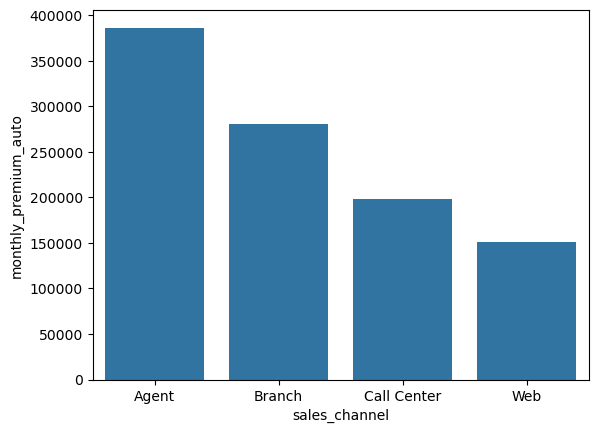

In [176]:
def revenue_per_sales_channel(df):
    df1 = df.copy()
    df1 = df1.groupby("sales_channel")["monthly_premium_auto"].sum().reset_index()
    df1["monthly_premium_auto"] = df1["monthly_premium_auto"].astype(float).round(2)
    #force to 2 decimals
    #df1.style.format({"monthly_premium_auto": "{:.2f}"})
    sales_plot = sns.barplot(data = df1, x= "sales_channel", y = 'monthly_premium_auto')
    
    
    
    return sales_plot

df1 = revenue_per_sales_channel(df)
df1


# 1. Insights:
"Agent" sales channel realized the highest revenues, follwoed by Branch, then Call center then Web. Meaning that human interaction is the best way to get better revenues.

2. Create a pivot table that shows the average customer lifetime value per gender and education level. Analyze the resulting table to draw insights.

# 2.  pivot table that shows the average customer lifetime value per gender

Pivot:


gender,education,F,M
0,Bachelor,7874.269478,7703.601675
1,College,7748.823325,8052.459288
2,Doctor,7328.508916,7415.333638
3,High School or Below,8675.220201,8149.687783
4,Master,8157.053154,8168.832659


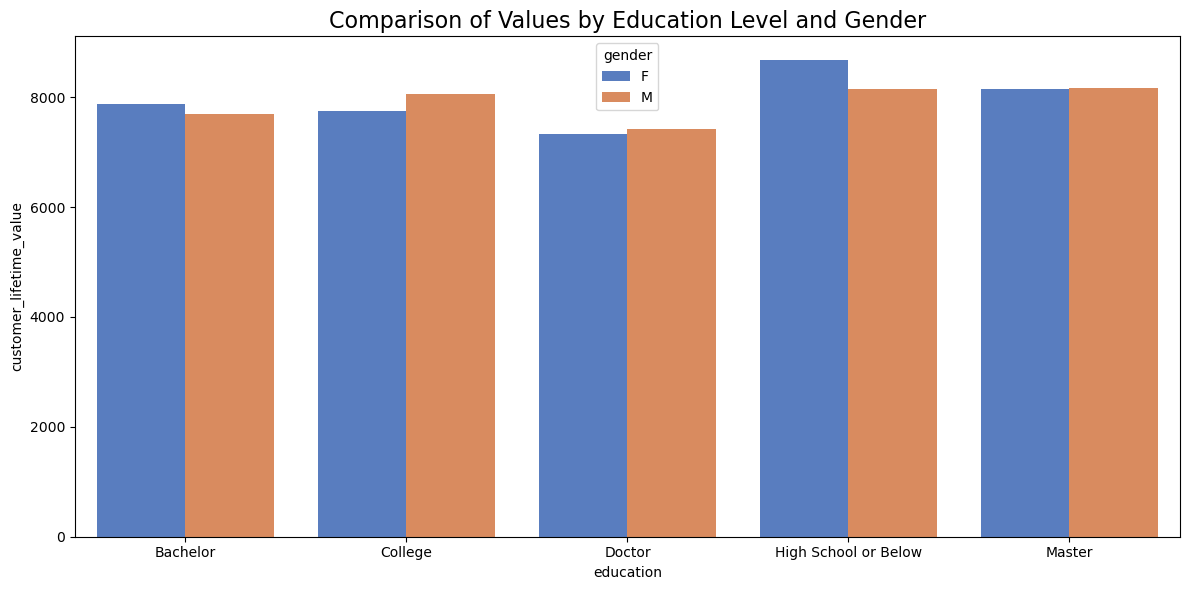

In [12]:
def life_timeby_gener_education(df):
    df1= df.copy()
    df1 = df1.groupby(["education", "gender"])["customer_lifetime_value"].mean().reset_index()
    df1_pivot = pd.pivot(data =df1, index = "education", columns = "gender", values = "customer_lifetime_value").reset_index()
    #print("df1:")
    #display(df1)
    print("Pivot:")
    display(df1_pivot)
    plt.figure(figsize=(12, 6))
    df1_plot = sns.barplot(data = df1, x = "education",y = "customer_lifetime_value", hue = "gender", palette = "muted")
    plt.title("Comparison of Values by Education Level and Gender", fontsize=16)
    plt.tight_layout()
    plt.show()    
                           
    return df1_plot
df1_plot = life_timeby_gener_education(df)


# Insights: 
Lower edcational individuals have the highest customer life time value, with women slightly more than men for this category. The other edicational categories have mainly the same C.L.T.V.

## Bonus

You work at the customer service department and you want to know which months had the highest number of complaints by policy type category. Create a summary table showing the number of complaints by policy type and month.
Show it in a long format table.

*In data analysis, a long format table is a way of structuring data in which each observation or measurement is stored in a separate row of the table. The key characteristic of a long format table is that each column represents a single variable, and each row represents a single observation of that variable.*

*More information about long and wide format tables here: https://www.statology.org/long-vs-wide-data/*

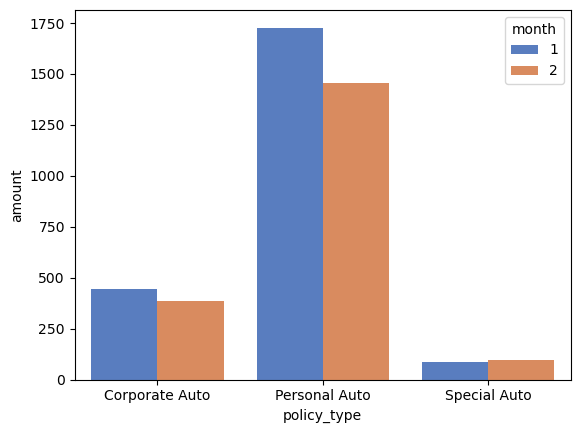

month,1,2
policy_type,,
Corporate Auto,443.434952,385.208135
Personal Auto,1727.605722,1453.684441
Special Auto,87.074049,95.226817


In [31]:
summary_table = df[['number_of_open_complaints', 'policy_type', 'month']]
summary_table = summary_table.groupby(['policy_type', 'month'])['number_of_open_complaints'].sum().rename("amount")

# This keeps 'policy_type' and 'month' as columns instead of index levels
summary_table_reset = summary_table.reset_index()

#summary_table = pd.pivot(data = summary_table,  columns = df['month'], values = 'amount')

my_plot = sns.barplot(data = summary_table_reset, x = 'policy_type', y = 'amount', hue = "month", palette = "muted")
plt.show()

df_pivot = summary_table.unstack(level='month')
display(df_pivot)
